# Лабораторная работа №1. Регрессия: предсказание качества вина

**Цель:** пройти полный цикл решения задачи регрессии - от анализа данных и baseline до сравнения моделей, анализа важности признаков и ошибок.

**Задача:** по физико-химическим свойствам вина предсказать оценку `quality`. Основная метрика - RMSE (порог: RMSE < 0.70), дополнительная - MAE.

**Данные:** [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (UCI), красное вино *Vinho Verde*.

| Признак | Что означает |
|---|---|
| `fixed acidity` | нелетучие кислоты (винная), г/дм³ |
| `volatile acidity` | летучие кислоты (уксусная), г/дм³; в избытке дают уксусный привкус |
| `citric acid` | лимонная кислота, г/дм³ |
| `residual sugar` | остаточный сахар, г/дм³ |
| `chlorides` | хлориды (соль), г/дм³ |
| `free sulfur dioxide` | свободный SO₂ (консервант), мг/дм³ |
| `total sulfur dioxide` | общий SO₂, мг/дм³ |
| `density` | плотность, г/см³ |
| `pH` | кислотность |
| `sulphates` | сульфаты, г/дм³ |
| `alcohol` | содержание спирта, % |
| **`quality`** | **целевая переменная**: медиана оценок дегустаторов, шкала 0-10 |

**План:** 1) настройки; 2) загрузка данных; 3) дубликаты; 4) разбиение train/test; 5) EDA; 6) метрики и схема эксперимента; 7) baseline; 8) линейная регрессия; 9) Random Forest; 10) Gradient Boosting; 11) сравнение моделей; 12) feature importance; 13) анализ ошибок; 14) модель для скрытого теста; 15) итоги; 16) ответы на вопросы из ТЗ.

## 1. Настройки
Все параметры эксперимента собраны в одной ячейке.

In [1]:
# Установка библиотек - нужна один раз, если их ещё нет (раскомментировать и выполнить):
# %pip install numpy pandas matplotlib seaborn joblib "scikit-learn>=1.4"

In [2]:
import io
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# параметры эксперимента 
RANDOM_STATE = 42   # одно зерно для разбиения, фолдов CV и всех моделей
TEST_SIZE = 0.2     # доля отложенной тестовой выборки
N_FOLDS = 5         # число фолдов кросс-валидации на train
WINE_TYPE = "red"   # "red" - красное, "white" - белое, "all" - оба датасета + признак is_red
TARGET = "quality"
RMSE_THRESHOLD = 0.70  # порог из ТЗ

DATA_DIR = Path("data")
MODEL_PATH = Path("model.joblib")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

sns.set_theme()  # стандартное оформление графиков seaborn
pd.set_option("display.precision", 4)

- `RANDOM_STATE = 42` используется везде, где есть случайность (разбиение, фолды CV, модели), поэтому результаты воспроизводимы.
- `WINE_TYPE` переключает датасет: `"red"` (по заданию), `"white"` или `"all"`. Для `"all"` добавляется признак `is_red`, потому что химический состав красных и белых вин сильно различается.
- Выводы в тексте написаны для красного вина.

## 2. Загрузка данных и первичный осмотр
Данные читаются из папки `data/`; если файла нет, он скачивается с UCI. Общий осмотр делаем на всём датасете: это только описание таблицы, параметры для модели здесь не вычисляются.

In [3]:
def read_wine_csv(color: str) -> pd.DataFrame:
    """Читает CSV красного или белого вина; если файла нет - скачивает архив с UCI."""
    path = DATA_DIR / f"winequality-{color}.csv"
    if not path.exists():
        print(f"{path} не найден - скачиваем архив с UCI")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        path.write_bytes(archive.read(path.name))
    return pd.read_csv(path, sep=";")  # в файлах UCI разделитель - точка с запятой


def load_wine(wine_type: str) -> pd.DataFrame:
    """Датасет выбранного типа: "red", "white" или "all" (оба набора + бинарный признак is_red)."""
    if wine_type in ("red", "white"):
        return read_wine_csv(wine_type)
    if wine_type == "all":
        red = read_wine_csv("red").assign(is_red=1)
        white = read_wine_csv("white").assign(is_red=0)
        data = pd.concat([red, white], ignore_index=True)
        # is_red ставим к признакам, quality остаётся последним столбцом
        return data[[c for c in data.columns if c != TARGET] + [TARGET]]
    raise ValueError(f"Неизвестный WINE_TYPE: {wine_type!r}")


df = load_wine(WINE_TYPE)
print(f"WINE_TYPE = {WINE_TYPE!r}: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

WINE_TYPE = 'red': 1599 строк, 12 столбцов


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Каждая строка - одно вино: 11 измерений и оценка `quality`. Строки 0 и 4 полностью совпадают - это дубликаты (раздел 3).

In [4]:
# типы, пропуски и число уникальных значений по каждому столбцу
overview = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "уникальных значений": df.nunique(),
})
overview

,тип,пропусков,уникальных значений
fixed acidity,float64,0,96
volatile acidity,float64,0,143
citric acid,float64,0,80
residual sugar,float64,0,91
chlorides,float64,0,153
free sulfur dioxide,float64,0,60
total sulfur dioxide,float64,0,144
density,float64,0,436
pH,float64,0,89
sulphates,float64,0,96


**Вывод:** все столбцы числовые, пропусков и категориальных признаков нет - заполнять и кодировать ничего не нужно.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile acidity,1599.0,0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,1599.0,0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual sugar,1599.0,2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1599.0,0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1599.0,15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total sulfur dioxide,1599.0,46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,1599.0,0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,1599.0,3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1599.0,0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000


**Вывод:**
- Масштабы признаков сильно различаются (`total sulfur dioxide` - до 289, `density` меняется в третьем знаке) → для линейной модели нужно масштабирование.
- У `residual sugar`, `chlorides`, `sulphates`, `total sulfur dioxide` максимум намного больше 75-го перцентиля → правая асимметрия и выбросы.
- `quality` принимает значения только от 3 до 8, хотя шкала 0-10.

## 3. Обработка дубликатов
Ищем полностью одинаковые строки (совпадают все признаки и `quality`).

In [6]:
feature_cols = [c for c in df.columns if c != TARGET]

is_extra_copy = df.duplicated(keep="first")   # True у 2-го, 3-го ... вхождения одной и той же строки
has_copy = df.duplicated(keep=False)          # True у всех строк, которые встречаются больше одного раза

print(f"Строк всего:                               {len(df)}")
print(f"Лишних копий (будут удалены):              {is_extra_copy.sum()} ({is_extra_copy.mean():.1%})")
print(f"Записей, которые встречаются > 1 раза:     {df[has_copy].drop_duplicates().shape[0]}")

# противоречивые дубликаты: одинаковые признаки, но разная оценка quality
conflicts = df.drop_duplicates().duplicated(subset=feature_cols).sum()
print(f"Одинаковые признаки, но разный quality:    {conflicts}")

print("\nСколько раз запись встречается в файле -> сколько таких записей:")
repeats = df[has_copy].value_counts().value_counts().sort_index()
for times, n_records in repeats.items():
    print(f"  {times} раза -> {n_records}")

Строк всего:                               1599
Лишних копий (будут удалены):              240 (15.0%)
Записей, которые встречаются > 1 раза:     220
Одинаковые признаки, но разный quality:    0

Сколько раз запись встречается в файле -> сколько таких записей:
  2 раза -> 204
  3 раза -> 12
  4 раза -> 4


**Вывод:** 240 лишних копий (15% данных) - 220 записей повторяются по 2-4 раза. Противоречивых дубликатов (одинаковые признаки, разный `quality`) нет, значит, это одни и те же записи, внесённые повторно.

In [7]:
# пример повторяющихся записей (индекс - номер строки в исходном CSV, считая с 0)
df[has_copy].sort_values(feature_cols).head(6)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


Например, строки 142 и 144 совпадают во всех столбцах.

In [8]:
# ИЛЛЮСТРАЦИЯ: разбиваем данные БЕЗ удаления дубликатов теми же параметрами, что будут дальше,
# и считаем, сколько тестовых строк имеют точную копию в train. Модели не обучаются,
# это разбиение дальше не используется.
raw_train, raw_test = train_test_split(
    df, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df[TARGET]
)
leaked = raw_test.merge(raw_train.drop_duplicates(), how="inner").shape[0]
print(f"Тестовых строк, у которых есть точная копия в train: {leaked} из {len(raw_test)} ({leaked / len(raw_test):.1%})")

Тестовых строк, у которых есть точная копия в train: 76 из 320 (23.8%)


**Что будет, если не удалить дубликаты:** у 76 из 320 тестовых вин (23.8%) окажется точная копия в train. Модель уже видела ответ для таких вин, и RMSE на test будет искусственно занижен.

**Почему удаляем до разбиения:**
- только так одно и то же вино не попадёт одновременно в train и test (и в разные фолды кросс-валидации);
- это **не** preprocessing на всём датасете: никакие статистики (среднее, std и т. п.) не вычисляются - строки только сравниваются на точное совпадение, и удаляются физически одинаковые записи.

In [9]:
n_before = len(df)
df = df.drop_duplicates(keep="first")  # исходный индекс сохраняем - по нему можно найти вино в CSV
print(f"До удаления: {n_before} строк, после: {len(df)} строк (удалено {n_before - len(df)})")
assert not df.duplicated().any()

До удаления: 1599 строк, после: 1359 строк (удалено 240)


Осталось 1359 уникальных вин. Исходный индекс сохранён - это номер строки в CSV.

## 4. Разбиение на train и test
Делим 80/20 со стратификацией по `quality` и `random_state=42`. Test используется один раз - для финальной оценки (раздел 11).

In [10]:
X = df.drop(columns=TARGET)
y = df[TARGET]
assert TARGET not in X.columns  # целевая переменная не попала в признаки

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,  # доли каждого значения quality в train и test одинаковы
)
print(f"train: {len(X_train)} объектов ({len(X_train) / len(X):.0%})")
print(f"test:  {len(X_test)} объектов ({len(X_test) / len(X):.0%})")
print(f"признаков: {X.shape[1]}")

train: 1087 объектов (80%)
test:  272 объектов (20%)
признаков: 11


- **Размер:** 1087 вин в train, 272 в test. Больший test оставил бы мало данных для обучения (особенно редких классов), меньший (≈136 вин) дал бы слишком шумную оценку.
- **Стратификация:** `quality` сильно несбалансирован (классов 3 и 8 всего 10 и 17 вин). Стратификация сохраняет одинаковые доли классов в train и test, иначе редкие классы могли бы вообще не попасть в test.
- **Почему test нельзя использовать многократно:** если выбирать модель по результату на test, решение подстроится под эти конкретные 272 вина, и оценка станет завышенной. Поэтому все решения принимаем по кросс-валидации на train.

In [11]:
# проверка стратификации: доли классов quality в train и test
class_table = pd.DataFrame({
    "весь датасет": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
    "доля в train, %": y_train.value_counts(normalize=True) * 100,
    "доля в test, %": y_test.value_counts(normalize=True) * 100,
}).sort_index()
class_table.index.name = "quality"
display(class_table.round(2))

max_gap = (class_table["доля в train, %"] - class_table["доля в test, %"]).abs().max()
print(f"Максимальное расхождение долей классов между train и test: {max_gap:.2f} п.п.")

# после удаления дубликатов ни одно вино не должно оказаться одновременно в train и test
overlap = X_test.merge(X_train, how="inner").shape[0]
print(f"Строк test, совпадающих с какой-либо строкой train: {overlap}")

,весь датасет,train,test,"доля в train, %","доля в test, %"
quality,,,,,
3,10,8,2,0.74,0.74
4,53,42,11,3.86,4.04
5,577,461,116,42.41,42.65
6,535,428,107,39.37,39.34
7,167,134,33,12.33,12.13
8,17,14,3,1.29,1.10


Максимальное расхождение долей классов между train и test: 0.24 п.п.
Строк test, совпадающих с какой-либо строкой train: 0


**Проверка:** доли классов в train и test совпадают с точностью до 0.24 п.п., пересечений между train и test нет, `quality` не входит в признаки.

## 5. Исследовательский анализ данных (только train)
Анализ, который влияет на решения, делаем только на train, чтобы test не участвовал в выборе модели.

### 5.1. Целевая переменная

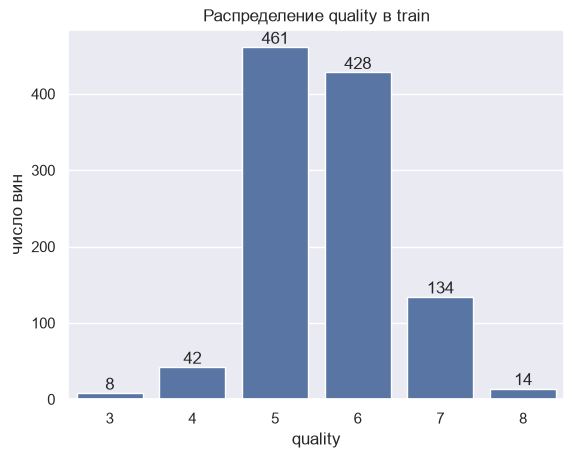

Среднее quality: 5.626, медиана: 6, std: 0.825
Доля классов 5 и 6: 81.8%


In [12]:
train_df = X_train.assign(**{TARGET: y_train})  # копия train с целевой переменной - только для EDA

ax = sns.countplot(x=y_train)
ax.bar_label(ax.containers[0])
ax.set_title("Распределение quality в train")
ax.set_ylabel("число вин")
plt.show()

print(f"Среднее quality: {y_train.mean():.3f}, медиана: {y_train.median():.0f}, std: {y_train.std():.3f}")
print(f"Доля классов 5 и 6: {y_train.isin([5, 6]).mean():.1%}")

**Вывод:**
- Классы 5 и 6 - 81.8% train, классы 3, 4 и 8 вместе - меньше 6%.
- Поэтому модель будет тянуть прогнозы к 5-6 и сильнее ошибаться на редких оценках.
- Среднее 5.626 - это прогноз baseline; std 0.825 - примерно его RMSE.

### 5.2. Распределения признаков

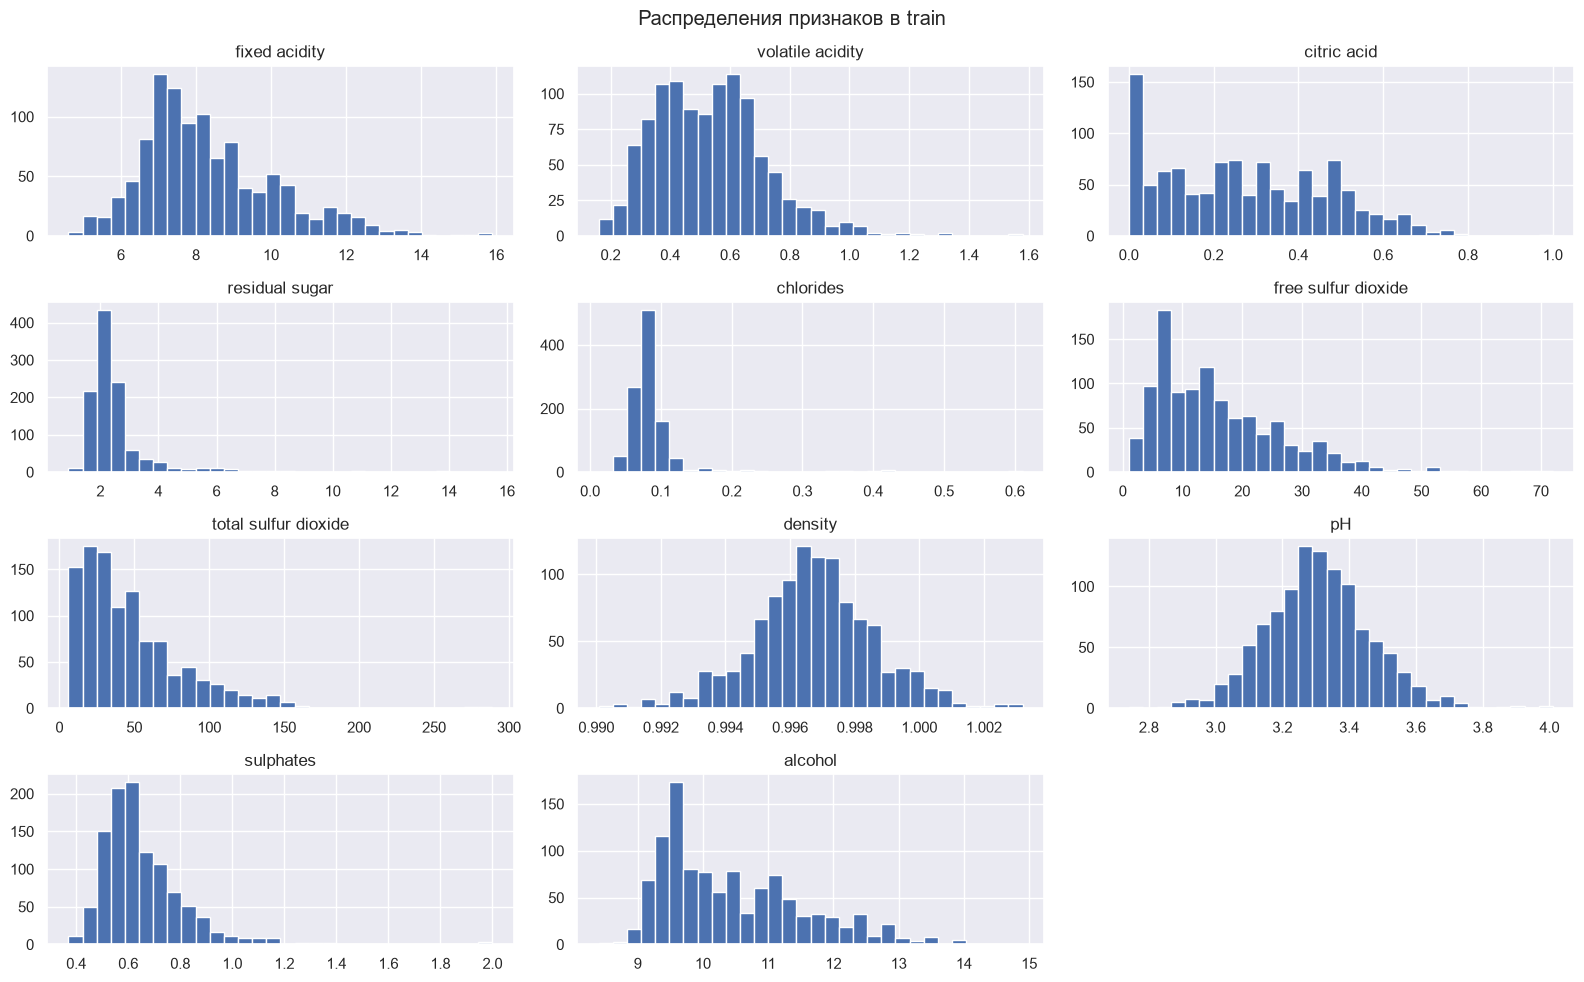

In [13]:
X_train.hist(bins=30, figsize=(16, 10))
plt.suptitle("Распределения признаков в train")
plt.tight_layout()
plt.show()

У `chlorides`, `residual sugar`, `sulphates` и SO₂ длинный правый хвост, `density` и `pH` распределены почти симметрично. Посчитаем асимметрию и долю выбросов.

In [14]:
# асимметрия и доля выбросов по правилу 1.5·IQR (за пределами [Q1 - 1.5·IQR, Q3 + 1.5·IQR])
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1 # межквартильный размах
outside = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr) # определение выбросов
shape_table = pd.DataFrame({
    "skew": X_train.skew(),
    "выбросов, %": outside.mean() * 100,
    "медиана": X_train.median(),
    "максимум": X_train.max(),
}).sort_values("skew", ascending=False)
shape_table.round(3)

,skew,"выбросов, %",медиана,максимум
chlorides,5.873,7.268,0.079,0.611
residual sugar,4.488,9.660,2.200,15.500
sulphates,2.499,4.232,0.620,2.000
total sulfur dioxide,1.590,3.404,38.000,289.000
free sulfur dioxide,1.234,1.656,14.000,72.000
fixed acidity,0.904,2.116,7.900,15.900
alcohol,0.881,0.552,10.200,14.900
volatile acidity,0.769,1.104,0.520,1.580
citric acid,0.338,0.092,0.260,1.000
pH,0.280,2.300,3.310,4.010


**Вывод:**
- Сильнее всего скошены `chlorides` (skew 5.9), `residual sugar` (4.5) и `sulphates` (2.5); у `residual sugar` почти 10% выбросов по правилу 1.5·IQR.
- Значения физически правдоподобны, это не ошибки измерений, поэтому выбросы не удаляем.
- Деревьям асимметрия не мешает (они используют пороги), линейная модель к выбросам чувствительнее.

### 5.3. Связь признаков с quality

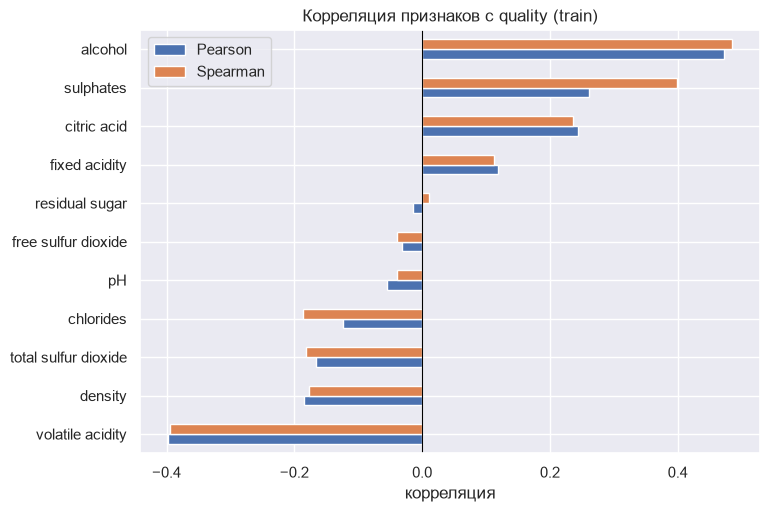

,Pearson,Spearman
alcohol,0.472,0.485
sulphates,0.261,0.399
volatile acidity,-0.397,-0.395
citric acid,0.244,0.236
chlorides,-0.124,-0.187
total sulfur dioxide,-0.165,-0.181
density,-0.184,-0.178
fixed acidity,0.119,0.112
pH,-0.055,-0.040
free sulfur dioxide,-0.032,-0.039


In [15]:
# связь каждого признака с quality: Пирсон - линейная, Спирмен - любая монотонная
corr_target = pd.DataFrame({
    "Pearson": X_train.corrwith(y_train),
    "Spearman": X_train.corrwith(y_train, method="spearman"),
})
corr_target.sort_values("Pearson").plot.barh(figsize=(8, 5.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Корреляция признаков с quality (train)")
plt.xlabel("корреляция")
plt.show()

corr_target.sort_values("Spearman", key=np.abs, ascending=False).round(3)

**Вывод:**
- `alcohol` - самая сильная связь (≈0.48): крепкие вина в среднем оценены выше. Но r² ≈ 0.22, то есть один признак объясняет лишь малую часть разброса - нужна комбинация признаков.
- `volatile acidity` - отрицательная связь (-0.40): уксусная кислота даёт неприятный привкус.
- `sulphates`: по Спирмену связь сильнее, чем по Пирсону (0.40 против 0.26) → зависимость нелинейная, деревья должны использовать её лучше линейной модели.
- `residual sugar`, `free sulfur dioxide`, `pH` почти не связаны с `quality`, но их не удаляем: корреляция не учитывает взаимодействия признаков.

### 5.4. Корреляции между признаками

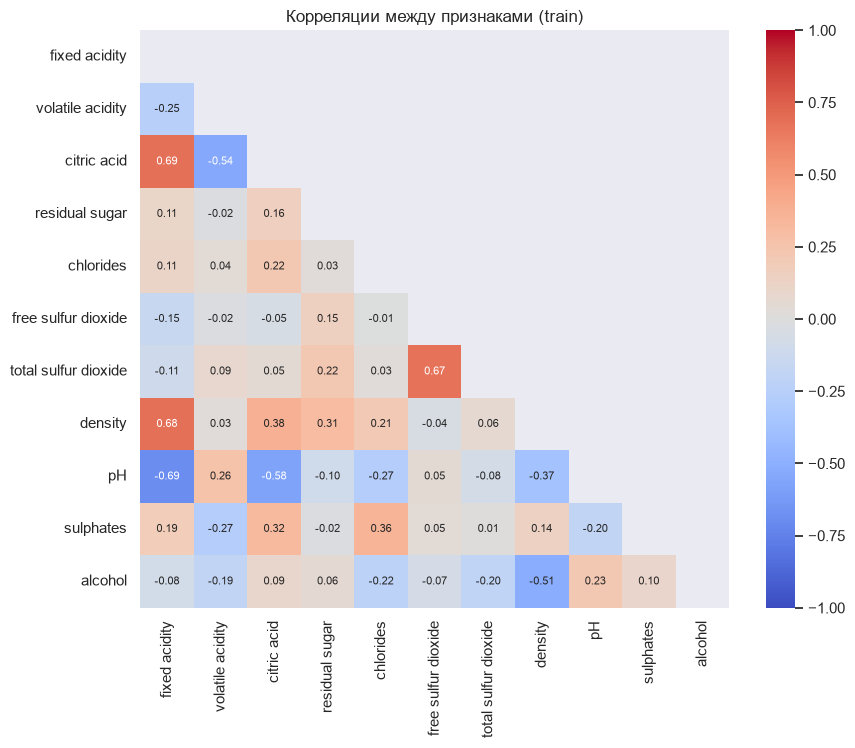

Пары признаков с |r| >= 0.5:
pH                    fixed acidity         -0.692
citric acid           fixed acidity          0.685
density               fixed acidity          0.682
total sulfur dioxide  free sulfur dioxide    0.674
pH                    citric acid           -0.576
citric acid           volatile acidity      -0.542
alcohol               density               -0.515


In [16]:
corr_matrix = X_train.corr()
upper = np.triu(np.ones_like(corr_matrix, dtype=bool))  # верхний треугольник дублирует нижний

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr_matrix, mask=upper, cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Корреляции между признаками (train)")
plt.grid(False)
plt.show()

pairs = corr_matrix.where(~upper).stack()
strong_pairs = pairs[pairs.abs() >= 0.5].sort_values(key=np.abs, ascending=False)
print("Пары признаков с |r| >= 0.5:")
print(strong_pairs.round(3).to_string())

**Вывод:**
- Сильно связаны признаки кислотности (`fixed acidity` с `citric acid`, `density` и `pH`, |r| ≈ 0.7), два вида SO₂ (0.67), `alcohol` и `density` (-0.52).
- Из-за этого коэффициенты линейной модели могут быть неустойчивыми, а важность в деревьях - делиться между похожими признаками.
- Пар с |r| > 0.9 нет, удалять признаки не нужно.

### 5.5. Ключевые признаки по значениям quality

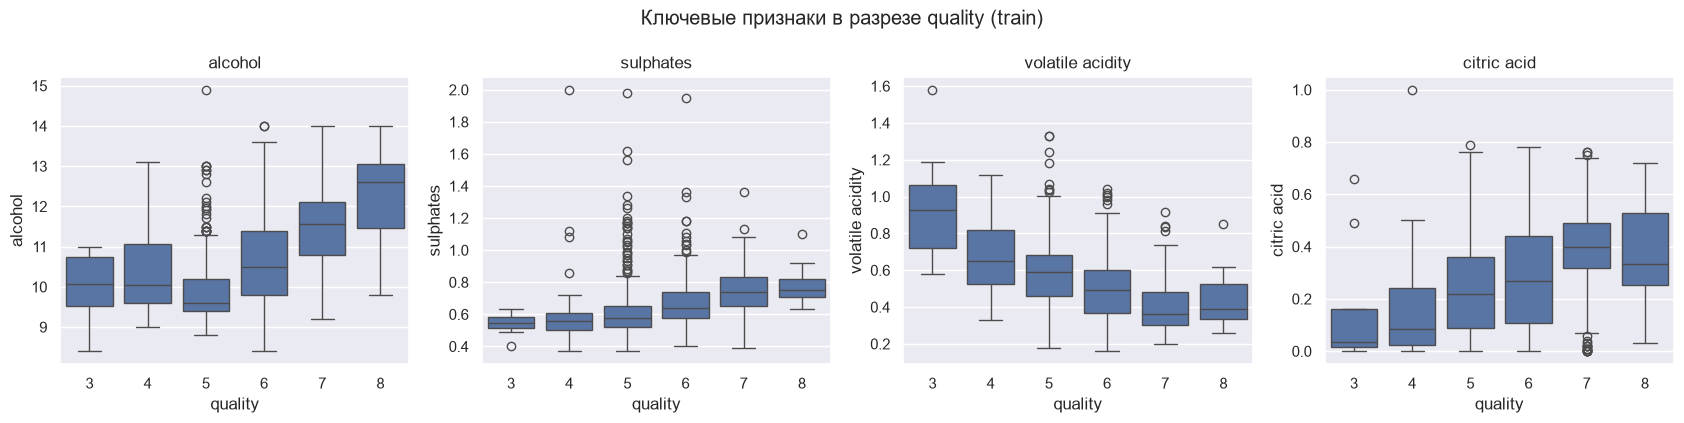

Число вин каждого класса в train: {3: 8, 4: 42, 5: 461, 6: 428, 7: 134, 8: 14}


,alcohol,sulphates,volatile acidity,citric acid
quality,,,,
3,10.075,0.545,0.928,0.035
4,10.050,0.560,0.653,0.085
5,9.600,0.580,0.590,0.220
6,10.500,0.640,0.490,0.270
7,11.550,0.740,0.360,0.400
8,12.600,0.750,0.390,0.335


In [17]:
# четыре признака с наибольшей |корреляцией Спирмена| с quality
top_eda = corr_target["Spearman"].abs().sort_values(ascending=False).index[:4].tolist()

fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, col in zip(axes, top_eda):
    sns.boxplot(data=train_df, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.suptitle("Ключевые признаки в разрезе quality (train)")
plt.tight_layout()
plt.show()

print("Число вин каждого класса в train:", y_train.value_counts().sort_index().to_dict())

# медианы признаков по классам - «типичный профиль» вина каждого качества
class_medians = train_df.groupby(TARGET)[X_train.columns].median()
class_medians[top_eda].round(3)

**Вывод:**
- `volatile acidity` падает с ростом качества (медиана 0.93 у класса 3 → 0.36 у класса 7) - главный признак плохого вина.
- `alcohol` растёт от 9.6 (класс 5) до 12.6 (класс 8), но у классов 3-4 он не ниже, чем у класса 5: алкоголь отличает хорошие вина от средних, но не плохие от средних.
- `sulphates` и `citric acid` растут с качеством.
- Ящики соседних классов сильно перекрываются, а классы 3 и 8 представлены всего 8 и 14 винами → идеального прогноза ждать не стоит.

### Итоги EDA (разведочный анализ данных)
- Ожидаем, что главными признаками будут `alcohol`, `volatile acidity` и `sulphates`.
- Есть нелинейные зависимости → деревья могут оказаться лучше линейной модели.
- Для Ridge нужен `StandardScaler`.
- На редких классах (3, 4, 8) ошибки будут больше.

## 6. Метрики и схема эксперимента
$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

- **MAE** - средняя абсолютная ошибка: на сколько баллов в среднем ошибается модель. Все ошибки входят линейно.
- **RMSE** - корень из средней квадратичной ошибки, тоже в баллах, но крупные ошибки весят больше. Это основная метрика.
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат - ошибка в 4 раза больше даёт в 16 раз больший вклад.
- **Почему MAE и RMSE различаются:** всегда RMSE ≥ MAE, равны они, только если все ошибки одинаковы по модулю. Чем больше крупных промахов, тем сильнее RMSE превышает MAE.

In [18]:
# два набора ошибок с одинаковым MAE: равномерные небольшие ошибки vs одна крупная
errors_even = np.array([0.5, 0.5, 0.5, 0.5])
errors_one_big = np.array([0.0, 0.0, 0.0, 2.0])
for name, e in [("равномерные ошибки", errors_even), ("одна крупная ошибка", errors_one_big)]:
    print(f"{name:20s}  ошибки = {e}  MAE = {np.mean(np.abs(e)):.2f}  RMSE = {np.sqrt(np.mean(e ** 2)):.2f}")

равномерные ошибки    ошибки = [0.5 0.5 0.5 0.5]  MAE = 0.50  RMSE = 0.50
одна крупная ошибка   ошибки = [0. 0. 0. 2.]  MAE = 0.50  RMSE = 1.00


При одинаковом MAE одна крупная ошибка увеличивает RMSE вдвое.

### Схема эксперимента

In [19]:
# одни и те же 5 фолдов для всех моделей: random_state фиксирован -> разбиение одинаковое при каждом вызове
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
cv_results = {}    # усреднённые результаты кросс-валидации всех моделей
cv_fold_rmse = {}  # RMSE каждой модели на каждом из фолдов


def run_cv(name, model):
    """Кросс-валидация модели на train. sklearn возвращает метрики со знаком минус - переворачиваем."""
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    summary = {
        "train RMSE": -res["train_rmse"].mean(),   # ошибка на обучающих фолдах
        "CV RMSE": -res["test_rmse"].mean(),       # ошибка на отложенных фолдах
        "CV RMSE std": res["test_rmse"].std(),     # разброс по фолдам
        "CV MAE": -res["test_mae"].mean(),
    }
    cv_results[name] = summary
    cv_fold_rmse[name] = -res["test_rmse"]
    return pd.Series(summary, name=name).round(4)

- Все решения (выбор `alpha`, выбор лучшей модели) принимаем по **5-fold кросс-валидации на train**.
- Фолды одинаковые для всех моделей (`random_state` фиксирован) - сравнение честное.
- `train RMSE` - ошибка на обучающих фолдах; большой разрыв с CV RMSE означает переобучение.
- Test используется **один раз** - в разделе 11.

## 7. Baseline
Baseline предсказывает одну константу для всех вин и показывает, извлекает ли модель из признаков что-то полезное.
- Для RMSE оптимально **среднее** (оно минимизирует сумму квадратов отклонений), для MAE - **медиана**.
- Основная метрика - RMSE, поэтому берём **среднее `quality` на train**. Проверим это на кросс-валидации.

In [20]:
# какая константа лучше для каждой метрики: среднее или медиана (сравниваем на CV по train)
const_rows = {}
for strategy in ("mean", "median"):
    res = cross_validate(DummyRegressor(strategy=strategy), X_train, y_train, cv=cv, scoring=SCORING)
    const_rows[strategy] = {"CV RMSE": -res["test_rmse"].mean(), "CV MAE": -res["test_mae"].mean()}

print(f"Среднее quality на train: {y_train.mean():.4f}, медиана: {y_train.median():.0f}")
pd.DataFrame(const_rows).T.round(4)

Среднее quality на train: 5.6256, медиана: 6


,CV RMSE,CV MAE
mean,0.8228,0.6954
median,0.9042,0.6725


Как и ожидалось: среднее даёт меньший RMSE (0.823 против 0.904), медиана - меньший MAE (0.673 против 0.695).

In [21]:
baseline = DummyRegressor(strategy="mean")  # всегда предсказывает среднее quality обучающей выборки
display(run_cv("Baseline (mean)", baseline))

baseline.fit(X_train, y_train)
print(f"Константа baseline (среднее по train): {baseline.predict(X_train.iloc[:1])[0]:.4f}")

train RMSE     0.8241
CV RMSE        0.8228
CV RMSE std    0.0611
CV MAE         0.6954
Name: Baseline (mean), dtype: float64

Константа baseline (среднее по train): 5.6256


**Вывод:** baseline всегда предсказывает 5.626, CV RMSE = 0.823. Модели должны быть заметно лучше этого значения. Результат baseline на test - в разделе 11.

## 8. Линейная регрессия (Ridge)
Модель: $\hat{y} = w_0 + w_1 x_1 + \dots + w_{11} x_{11}$. Ridge добавляет к MSE штраф $\alpha \sum_j w_j^2$, который стабилизирует веса при коррелированных признаках.

### 8.1. Зачем масштабирование
Посмотрим на коэффициенты обычной линейной регрессии без масштабирования.

In [22]:
# обычная линейная регрессия БЕЗ масштабирования (обучение только на train)
ols_raw = LinearRegression().fit(X_train, y_train)
std_train = X_train.std(ddof=0)
coef_trap = pd.DataFrame({
    "коэффициент (исходные единицы)": ols_raw.coef_,
    "std признака": std_train,
    "коэффициент × std": ols_raw.coef_ * std_train,
}, index=X_train.columns).sort_values("коэффициент (исходные единицы)", key=np.abs, ascending=False)
coef_trap.round(4)

,коэффициент (исходные единицы),std признака,коэффициент × std
density,-7.9223,0.0019,-0.0152
chlorides,-1.9506,0.0476,-0.0929
volatile acidity,-1.0099,0.1856,-0.1875
sulphates,0.8720,0.1695,0.1478
pH,-0.3557,0.1588,-0.0565
alcohol,0.2829,1.0963,0.3101
citric acid,0.0731,0.1965,0.0144
residual sugar,-0.0154,1.3463,-0.0207
fixed acidity,0.0122,1.7885,0.0218
free sulfur dioxide,0.0050,10.6108,0.0535


**Вывод:** без масштабирования самым «важным» кажется `density` (-7.9), а `alcohol` - только на 6-м месте. Это иллюзия: коэффициент показывает эффект изменения признака на 1 единицу, а `density` меняется всего на ≈0.002. С учётом масштаба (коэффициент × std) эффект `alcohol` - 0.31, а `density` - 0.015.

Поэтому:
- сравнивать коэффициенты признаков в разных единицах нельзя;
- для Ridge масштабирование нужно ещё и потому, что штраф одинаков для всех весов.

Используем `StandardScaler` внутри `Pipeline`: он обучается только на train (в CV - только на обучающих фолдах).

### 8.2. Подбор alpha по кросс-валидации на train

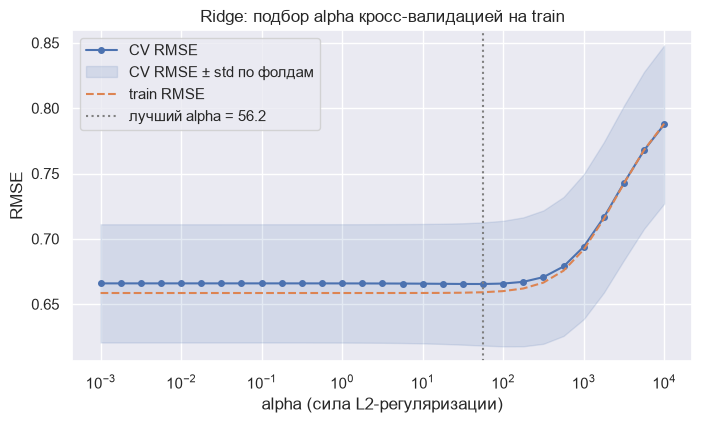

Лучший alpha: 56.23
CV RMSE при alpha = 0.001 (почти без регуляризации): 0.6659
CV RMSE при лучшем alpha:                         0.6654


In [23]:
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),  # mean/std считаются только по обучающей части каждого фолда
    ("ridge", Ridge()),
])
alpha_grid = np.logspace(-3, 4, 29)
ridge_search = GridSearchCV(
    ridge_pipe,
    param_grid={"ridge__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    return_train_score=True,
)
ridge_search.fit(X_train, y_train)
best_alpha = ridge_search.best_params_["ridge__alpha"]

search_res = pd.DataFrame(ridge_search.cv_results_)
cv_curve = -search_res["mean_test_score"]
train_curve = -search_res["mean_train_score"]
cv_std = search_res["std_test_score"]

plt.figure(figsize=(8, 4.3))
line, = plt.plot(alpha_grid, cv_curve, marker="o", markersize=4, label="CV RMSE")
plt.fill_between(alpha_grid, cv_curve - cv_std, cv_curve + cv_std, color=line.get_color(), alpha=0.15,
                 label="CV RMSE ± std по фолдам")
plt.plot(alpha_grid, train_curve, linestyle="--", label="train RMSE")
plt.axvline(best_alpha, color="gray", linestyle=":", label=f"лучший alpha = {best_alpha:.3g}")
plt.xscale("log")
plt.xlabel("alpha (сила L2-регуляризации)")
plt.ylabel("RMSE")
plt.title("Ridge: подбор alpha кросс-валидацией на train")
plt.legend()
plt.show()

print(f"Лучший alpha: {best_alpha:.4g}")
print(f"CV RMSE при alpha = {alpha_grid[0]:g} (почти без регуляризации): {cv_curve.iloc[0]:.4f}")
print(f"CV RMSE при лучшем alpha:                         {cv_curve.min():.4f}")

**Вывод:**
- При alpha < 100 ошибка почти не меняется (CV RMSE ≈ 0.665): признаков мало, данных достаточно, и регуляризация почти ничего не даёт.
- При alpha > 1000 растут обе ошибки - это недообучение: веса сжимаются к нулю.
- Лучший alpha ≈ 56.

### 8.3. Качество на кросс-валидации

In [24]:
ridge = ridge_search.best_estimator_  # Pipeline(StandardScaler -> Ridge(best_alpha)), обучен на всём train
run_cv("Linear Regression (Ridge)", ridge)

train RMSE     0.6591
CV RMSE        0.6654
CV RMSE std    0.0471
CV MAE         0.5166
Name: Linear Regression (Ridge), dtype: float64

**Вывод:** CV RMSE = 0.665 против 0.823 у baseline - модель полезна. Ошибки на train и CV почти равны (0.659 и 0.665): переобучения нет, но модель слишком простая (недообучение) - она не учитывает нелинейные зависимости, найденные в EDA.

### 8.4. Коэффициенты

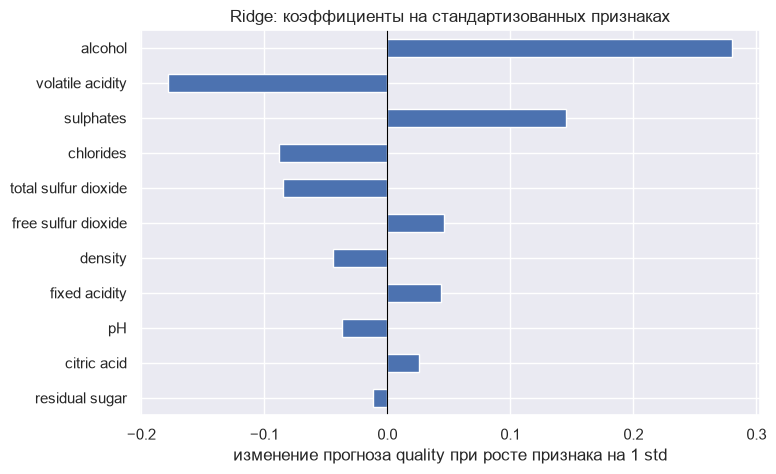

Свободный член w0 = 5.6256 (= среднее quality на train)


alcohol                 0.2801
volatile acidity       -0.1780
sulphates               0.1449
chlorides              -0.0883
total sulfur dioxide   -0.0847
free sulfur dioxide     0.0458
density                -0.0446
fixed acidity           0.0434
pH                     -0.0372
citric acid             0.0259
residual sugar         -0.0117
dtype: float64

In [25]:
ridge_coef = pd.Series(ridge.named_steps["ridge"].coef_, index=X_train.columns)

ridge_coef.reindex(ridge_coef.abs().sort_values().index).plot.barh(figsize=(8, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("изменение прогноза quality при росте признака на 1 std")
plt.title("Ridge: коэффициенты на стандартизованных признаках")
plt.show()

print(f"Свободный член w0 = {ridge.named_steps['ridge'].intercept_:.4f} (= среднее quality на train)")
ridge_coef.sort_values(key=np.abs, ascending=False).round(4)

**Вывод:** коэффициент - это изменение прогноза при росте признака на 1 std при прочих равных.
- Сильнее всего влияют `alcohol` (+0.28), `volatile acidity` (-0.18) и `sulphates` (+0.14) - как и в EDA.
- `citric acid` в EDA был связан с качеством (0.24), а в модели его вес почти нулевой: эту информацию уже несут коррелированные с ним `volatile acidity` и `fixed acidity`.
- Коэффициенты описывают связь внутри модели, а не причину.

## 9. Random Forest
Случайный лес усредняет прогнозы многих деревьев, каждое из которых обучено на бутстрэп-выборке. Деревья улавливают нелинейные зависимости и взаимодействия признаков, а усреднение уменьшает их переобучение. Масштабирование не нужно.

Гиперпараметры фиксированные: `n_estimators=300`, `max_depth=None`.

In [26]:
rf = RandomForestRegressor(
    n_estimators=300,   # число деревьев: больше -> стабильнее среднее, дольше обучение
    max_depth=None,     # деревья растут без ограничения глубины; разброс гасится усреднением
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
display(run_cv("Random Forest", rf))
rf.fit(X_train, y_train)  # финальное обучение на всём train

train RMSE     0.2412
CV RMSE        0.6437
CV RMSE std    0.0395
CV MAE         0.4937
Name: Random Forest, dtype: float64

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

**Вывод:** CV RMSE = 0.644 - лучше Ridge (0.665). Ошибка на train всего 0.241: глубокие деревья запоминают обучающие данные. Но ошибка на новых данных при этом самая низкая, значит вредного переобучения нет - качество леса оцениваем по CV.

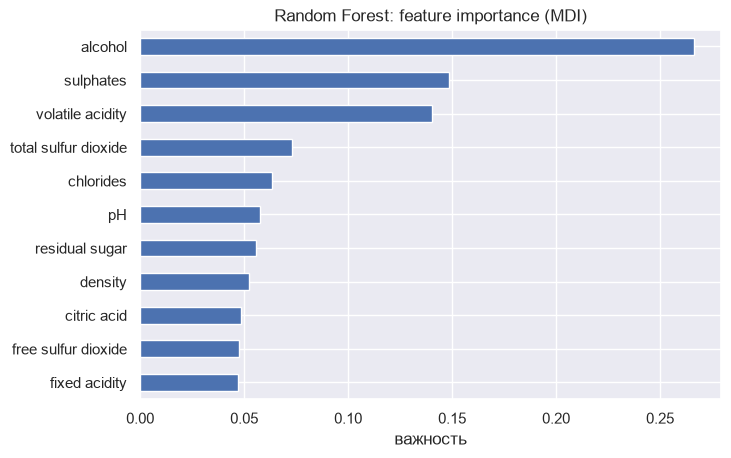

alcohol                 0.2662
sulphates               0.1483
volatile acidity        0.1403
total sulfur dioxide    0.0732
chlorides               0.0635
pH                      0.0575
residual sugar          0.0557
density                 0.0522
citric acid             0.0485
free sulfur dioxide     0.0474
fixed acidity           0.0472
dtype: float64

In [27]:
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns)

rf_importance.sort_values().plot.barh(figsize=(7.5, 4.8))
plt.xlabel("важность")
plt.title("Random Forest: feature importance (MDI)")
plt.show()

rf_importance.sort_values(ascending=False).round(4)

**Feature importance (MDI)** - насколько в среднем уменьшается ошибка в разбиениях по признаку; сумма важностей равна 1.

**Вывод:**
- Топ-3: `alcohol` (0.27), `sulphates` (0.15), `volatile acidity` (0.14) - те же признаки, что в EDA и у Ridge.
- `sulphates` у леса на 2-м месте (у Ridge - на 3-м): деревья лучше используют его нелинейную связь с качеством.
- MDI считается на train и может завышать важность второстепенных признаков - проверим это в разделе 12.

## 10. Gradient Boosting
Бустинг строит деревья последовательно: каждое новое дерево исправляет ошибки предыдущих с шагом `learning_rate`.

Фиксированные гиперпараметры: `n_estimators=200`, `learning_rate=0.05`, `max_depth=3` - много небольших шагов неглубокими деревьями.

In [28]:
gb = GradientBoostingRegressor(
    n_estimators=200,    # число последовательных деревьев
    learning_rate=0.05,  # вклад каждого дерева; маленький шаг -> плавнее обучение, меньше переобучение
    max_depth=3,         # неглубокие деревья: каждое ловит взаимодействия максимум 3 признаков
    random_state=RANDOM_STATE,
)
display(run_cv("Gradient Boosting", gb))
gb.fit(X_train, y_train)

train RMSE     0.4688
CV RMSE        0.6620
CV RMSE std    0.0284
CV MAE         0.5139
Name: Gradient Boosting, dtype: float64

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

**Вывод:** CV RMSE = 0.662 - лучше Ridge, но хуже леса. Разрыв train/CV меньше, чем у леса (0.469 и 0.662): неглубокие деревья и маленький шаг не дают сильно переобучиться.

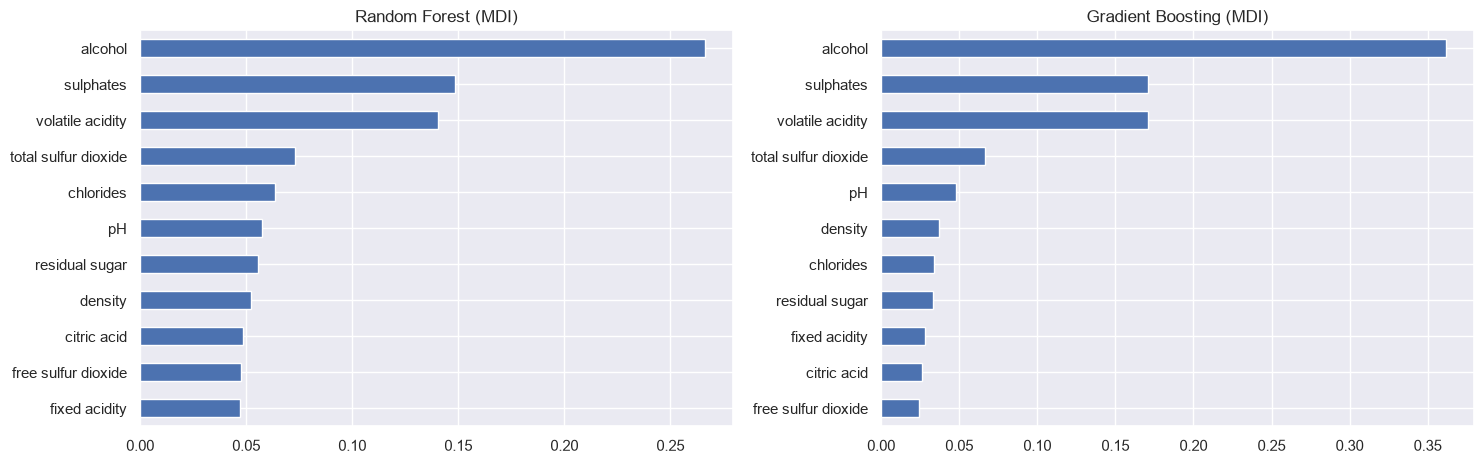

,RF importance,GB importance,RF ранг,GB ранг
alcohol,0.2662,0.3616,1,1
sulphates,0.1483,0.1712,2,2
volatile acidity,0.1403,0.1709,3,3
total sulfur dioxide,0.0732,0.0664,4,4
chlorides,0.0635,0.0335,5,7
pH,0.0575,0.0477,6,5
residual sugar,0.0557,0.0331,7,8
density,0.0522,0.0373,8,6
citric acid,0.0485,0.0262,9,10
free sulfur dioxide,0.0474,0.0241,10,11


In [29]:
gb_importance = pd.Series(gb.feature_importances_, index=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
rf_importance.sort_values().plot.barh(ax=axes[0], title="Random Forest (MDI)")
gb_importance.sort_values().plot.barh(ax=axes[1], title="Gradient Boosting (MDI)")
plt.tight_layout()
plt.show()

rf_vs_gb = pd.DataFrame({
    "RF importance": rf_importance,
    "GB importance": gb_importance,
    "RF ранг": rf_importance.rank(ascending=False).astype(int),
    "GB ранг": gb_importance.rank(ascending=False).astype(int),
}).sort_values("RF importance", ascending=False)
rf_vs_gb.round(4)

**Вывод (RF и GB):**
- Топ-4 совпадает, причём в том же порядке: `alcohol`, `sulphates`, `volatile acidity`, `total sulfur dioxide`. Разные алгоритмы выделили одни и те же признаки - значит, основной сигнал именно в них.
- Бустинг сильнее концентрирует важность на главных признаках (`alcohol`: 0.36 против 0.27).
- Порядок остальных признаков у моделей разный - их вклад мал и неустойчив.

## 11. Честное сравнение моделей
Все модели обучены на одном train, сравниваются на одних и тех же фолдах CV и на одном test. Лучшая модель выбирается по CV, test - только для финальной оценки.

In [30]:
models = {
    "Baseline (mean)": baseline,
    "Linear Regression (Ridge)": ridge,
    "Random Forest": rf,
    "Gradient Boosting": gb,
}

# 1) выбор модели - только по кросс-валидации на train
cv_table = pd.DataFrame(cv_results).T.sort_values("CV RMSE")
cv_table.index.name = "Модель"
best_name = cv_table.index[0]
display(cv_table.round(4))
print(f"Лучшая модель по CV RMSE: {best_name}")

# RMSE по фолдам: фолды одинаковые для всех моделей, поэтому сравнение попарное
fold_table = pd.DataFrame(cv_fold_rmse, index=[f"фолд {i + 1}" for i in range(N_FOLDS)]).T.loc[cv_table.index]
display(fold_table.round(4))
for name in cv_table.index[1:]:
    wins = (fold_table.loc[best_name] < fold_table.loc[name]).sum()
    print(f"{best_name} лучше, чем {name}, на {wins} из {N_FOLDS} фолдов")

,train RMSE,CV RMSE,CV RMSE std,CV MAE
Модель,,,,
Random Forest,0.2412,0.6437,0.0395,0.4937
Gradient Boosting,0.4688,0.6620,0.0284,0.5139
Linear Regression (Ridge),0.6591,0.6654,0.0471,0.5166
Baseline (mean),0.8241,0.8228,0.0611,0.6954


Лучшая модель по CV RMSE: Random Forest


,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
Модель,,,,,
Random Forest,0.6042,0.6044,0.6353,0.6668,0.7078
Gradient Boosting,0.6480,0.6313,0.6389,0.6914,0.7005
Linear Regression (Ridge),0.6259,0.6326,0.6332,0.6864,0.7490
Baseline (mean),0.7820,0.8061,0.7588,0.8324,0.9347


Random Forest лучше, чем Gradient Boosting, на 4 из 5 фолдов
Random Forest лучше, чем Linear Regression (Ridge), на 4 из 5 фолдов
Random Forest лучше, чем Baseline (mean), на 5 из 5 фолдов


**Вывод:** лучшая по CV - **Random Forest** (0.644). Разница с GB (0.018) меньше разброса по фолдам, но на одинаковых фолдах RF лучше в 4 случаях из 5 - преимущество небольшое, но устойчивое.

На фолде 5 ошибка у всех моделей выше обычной (даже у baseline - 0.935), у леса там 0.708. Значит, на конкретной выборке результат может колебаться на несколько сотых.

In [31]:
# 2) однократная финальная оценка: все модели обучены на одном train и проверяются на одном test
test_pred = {name: model.predict(X_test) for name, model in models.items()}

results = pd.DataFrame({
    "RMSE": {name: root_mean_squared_error(y_test, p) for name, p in test_pred.items()},
    "MAE": {name: mean_absolute_error(y_test, p) for name, p in test_pred.items()},
}).sort_values("RMSE")
results.index.name = "Модель"
results.round(4)

,RMSE,MAE
Модель,,
Random Forest,0.6264,0.4797
Gradient Boosting,0.6337,0.4965
Linear Regression (Ridge),0.6547,0.5106
Baseline (mean),0.8191,0.6921


**Итоговая таблица:** порядок моделей на test такой же, как на CV, - выбор лучшей модели подтвердился.

,CV RMSE,CV RMSE std,test RMSE,"улучшение RMSE к baseline, %",лучше baseline,RMSE < 0.7
Модель,,,,,,
Random Forest,0.6437,0.0395,0.6264,23.5289,True,True
Gradient Boosting,0.6620,0.0284,0.6337,22.6409,True,True
Linear Regression (Ridge),0.6654,0.0471,0.6547,20.0783,True,True
Baseline (mean),0.8228,0.0611,0.8191,0.0000,False,False


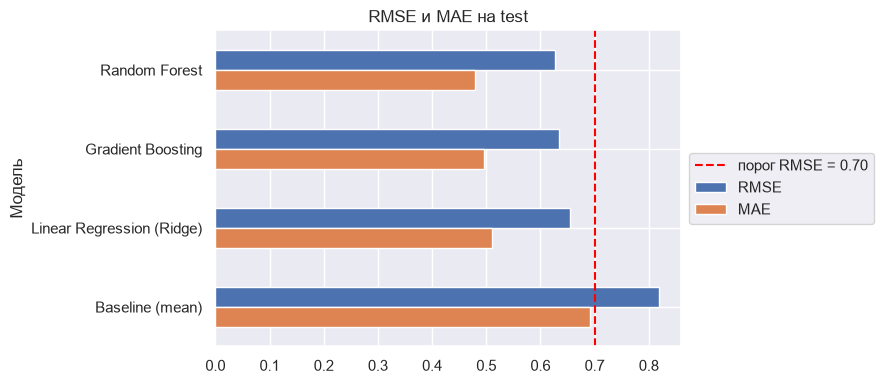

In [32]:
base_rmse = results.loc["Baseline (mean)", "RMSE"]
comparison = pd.DataFrame({
    "CV RMSE": cv_table["CV RMSE"],
    "CV RMSE std": cv_table["CV RMSE std"],
    "test RMSE": results["RMSE"],
    "улучшение RMSE к baseline, %": (1 - results["RMSE"] / base_rmse) * 100,
    "лучше baseline": results["RMSE"] < base_rmse,
    f"RMSE < {RMSE_THRESHOLD}": results["RMSE"] < RMSE_THRESHOLD,
}).loc[results.index]
display(comparison.round(4))

ax = results.plot.barh(figsize=(9, 4))
ax.axvline(RMSE_THRESHOLD, color="red", linestyle="--", label=f"порог RMSE = {RMSE_THRESHOLD:.2f}")
ax.invert_yaxis()  # лучшая модель - сверху
ax.set_title("RMSE и MAE на test")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**Вывод:**
- **Все три модели лучше baseline** и проходят порог 0.70: RMSE снизился на 20.1% (Ridge), 22.6% (GB) и 23.5% (RF).
- Test RMSE у всех моделей в пределах «CV RMSE ± std» - признаков утечки нет.
- **Ridge** хуже всех: он учитывает только линейные зависимости, а в данных есть нелинейные (сульфаты, алкоголь).
- **Деревья** улавливают нелинейности и взаимодействия признаков. Лес немного лучше бустинга: усреднение многих деревьев хорошо сглаживает шум в субъективных оценках.
- Даже у лучшей модели MAE ≈ 0.48: химических признаков недостаточно, чтобы полностью объяснить оценку дегустаторов.

## 12. Feature importance: сравнение моделей
Чтобы сравнить модели на одной шкале, модули коэффициентов Ridge нормируем к сумме 1, как MDI у деревьев.

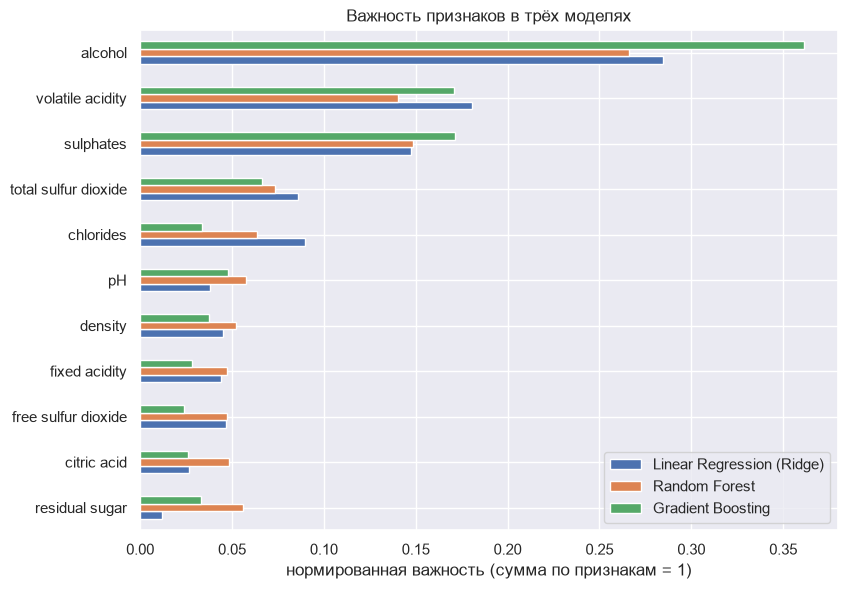

In [33]:
ridge_abs = ridge_coef.abs()
fi_table = pd.DataFrame({
    "Linear Regression (Ridge)": ridge_abs / ridge_abs.sum(),  # |коэф.|, нормированные к сумме 1
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance,
})
order = fi_table.mean(axis=1).sort_values().index

fi_table.loc[order].plot.barh(figsize=(9, 6.5))
plt.xlabel("нормированная важность (сумма по признакам = 1)")
plt.title("Важность признаков в трёх моделях")
plt.show()

**Вывод:** все три модели ставят на первые места `alcohol`, `volatile acidity` и `sulphates`. Но коэффициенты и MDI получены на train, поэтому дополнительно считаем permutation importance на test.

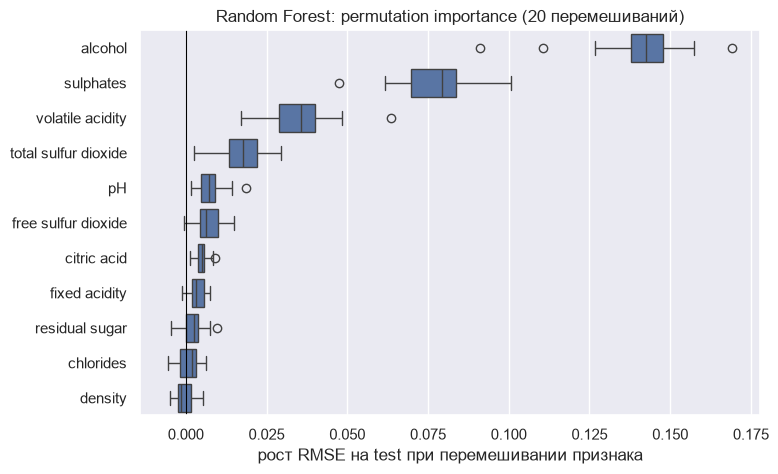

,Linear Regression (Ridge),Random Forest,Gradient Boosting
alcohol,0.1172,0.1403,0.1391
sulphates,0.0357,0.0780,0.0727
volatile acidity,0.0435,0.0349,0.0328
total sulfur dioxide,0.0146,0.0177,0.0239
pH,0.0010,0.0077,0.0053
free sulfur dioxide,-0.0020,0.0069,0.0043
citric acid,-0.0025,0.0049,0.0017
fixed acidity,-0.0004,0.0036,0.0035
residual sugar,-0.0016,0.0024,0.0047
chlorides,0.0216,0.0011,0.0014


In [34]:
# permutation importance на test: на сколько вырастает RMSE, если случайно перемешать значения признака.
# Это АНАЛИЗ уже выбранных и обученных моделей; никакие решения по нему не принимаются.
perm_raw = {}
for name in ["Linear Regression (Ridge)", "Random Forest", "Gradient Boosting"]:
    perm_raw[name] = permutation_importance(
        models[name], X_test, y_test,
        scoring="neg_root_mean_squared_error", n_repeats=20, random_state=RANDOM_STATE,
    )
perm_table = pd.DataFrame({name: r.importances_mean for name, r in perm_raw.items()}, index=X_test.columns)

order = perm_table[best_name].sort_values(ascending=False).index  # самый важный - сверху
repeats = pd.DataFrame(perm_raw[best_name].importances.T, columns=X_test.columns)[order]
plt.figure(figsize=(8, 5))
sns.boxplot(data=repeats, orient="h", color="C0")  # один цвет для всех признаков
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("рост RMSE на test при перемешивании признака")
plt.title(f"{best_name}: permutation importance (20 перемешиваний)")
plt.show()

perm_table.sort_values(best_name, ascending=False).round(4)

**Permutation importance** - на сколько растёт RMSE на test, если перемешать значения признака. Это анализ уже выбранных моделей: по нему ничего не выбирается, поэтому это не подгонка под test.

**Вывод:**
- Для RF важнее всего `alcohol` (RMSE растёт на 0.14), `sulphates` (0.08), `volatile acidity` (0.035), `total sulfur dioxide` (0.018) - тот же топ-4, что по MDI.
- `chlorides` по MDI у леса на 5-м месте, а по перестановке - почти 0: MDI завысил его важность, лес подгонялся под шум в этом признаке.

In [35]:
# ранги признаков (1 - самый важный) по всем методам + связь с quality из EDA
rank_table = pd.DataFrame({
    "EDA |Spearman|": corr_target["Spearman"].abs(),
    "Ridge |coef|": ridge_abs,
    "RF MDI": rf_importance,
    "GB MDI": gb_importance,
    "RF perm.": perm_table["Random Forest"],
    "GB perm.": perm_table["Gradient Boosting"],
    "Ridge perm.": perm_table["Linear Regression (Ridge)"],
}).rank(ascending=False).astype(int)
rank_table["средний ранг"] = rank_table.mean(axis=1).round(1)
rank_table = rank_table.sort_values("средний ранг")
top_features = rank_table.index[:4].tolist()
print("Топ-4 признака по среднему рангу:", top_features)
rank_table

Топ-4 признака по среднему рангу: ['alcohol', 'sulphates', 'volatile acidity', 'total sulfur dioxide']


,EDA |Spearman|,Ridge |coef|,RF MDI,GB MDI,RF perm.,GB perm.,Ridge perm.,средний ранг
alcohol,1,1,1,1,1,1,1,1.0
sulphates,2,3,2,2,2,2,3,2.3
volatile acidity,3,2,3,3,3,3,2,2.7
total sulfur dioxide,6,5,4,4,4,4,5,4.6
chlorides,5,4,5,7,10,11,4,6.6
pH,9,9,6,5,5,6,7,6.7
density,7,7,8,6,11,5,6,7.1
fixed acidity,8,8,11,9,8,9,8,8.7
citric acid,4,10,9,10,7,10,11,8.7
free sulfur dioxide,10,6,10,11,6,8,10,8.7


**Сравнение с EDA:**
- Тройка лидеров совпадает с EDA во всех моделях.
- `citric acid` заметен в EDA, но не в моделях - его информацию дублируют другие признаки кислотности.
- `total sulfur dioxide` в моделях важнее, чем в EDA: его эффект виден, когда остальные признаки уже учтены.

### Можно ли по feature importance утверждать причинность?
**Нет.** Важность показывает, насколько модель использует признак, то есть статистическую связь в данных:
- данные наблюдательные - никто не менял один признак при прочих равных;
- возможны скрытые общие причины: например, спелость винограда влияет и на крепость, и на вкус;
- коррелированные признаки взаимозаменяемы, и важность делится между ними произвольно;
- важность зависит от модели (`chlorides` важен для Ridge, но не для леса), а реальная причина от модели не зависит.

Причинность можно проверить только экспериментом.

## 13. Анализ ошибок лучшей модели (Random Forest)
Разбираем ошибки на test; модель после этого не меняется.

Модель: Random Forest
Средняя ошибка (смещение):         +0.033
Медианная |ошибка|:                0.393
|ошибка| < 0.5:                    61.0% объектов
|ошибка| < 1.0:                    89.3% объектов
|ошибка| >= 1.5:                   6 объектов
Максимальная |ошибка|:             2.187
Разброс истинных quality (std):    0.821
Разброс прогнозов (std):           0.538
Диапазон прогнозов:                [4.37; 7.23]


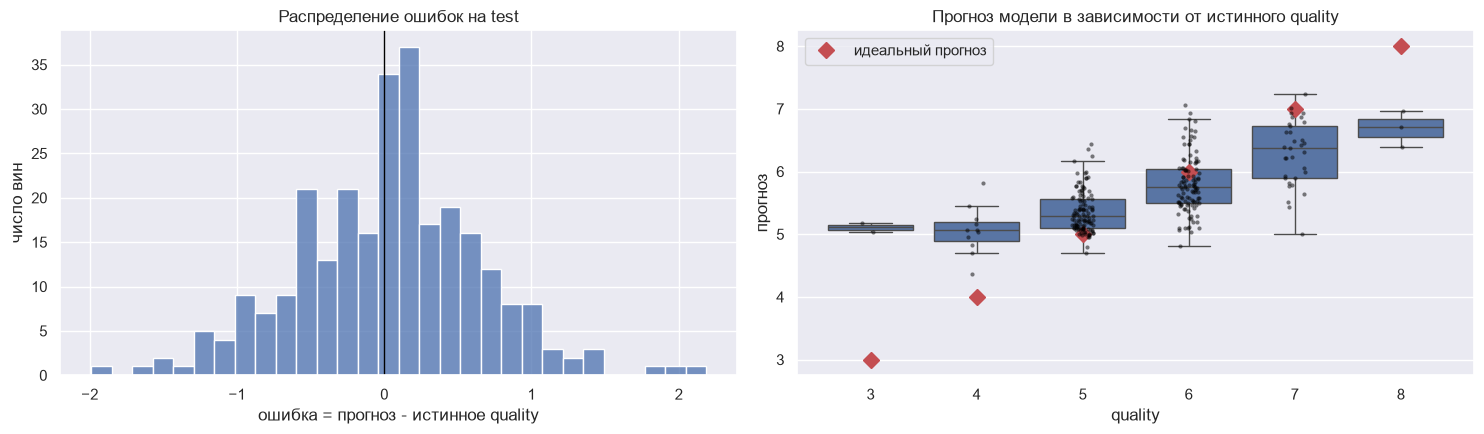

In [36]:
best_model = models[best_name]
pred = pd.Series(test_pred[best_name], index=y_test.index)
error = pred - y_test  # > 0 - модель завысила оценку, < 0 - занизила
abs_error = error.abs()

print(f"Модель: {best_name}")
print(f"Средняя ошибка (смещение):         {error.mean():+.3f}")
print(f"Медианная |ошибка|:                {abs_error.median():.3f}")
print(f"|ошибка| < 0.5:                    {(abs_error < 0.5).mean():.1%} объектов")
print(f"|ошибка| < 1.0:                    {(abs_error < 1.0).mean():.1%} объектов")
print(f"|ошибка| >= 1.5:                   {(abs_error >= 1.5).sum()} объектов")
print(f"Максимальная |ошибка|:             {abs_error.max():.3f}")
print(f"Разброс истинных quality (std):    {y_test.std():.3f}")
print(f"Разброс прогнозов (std):           {pred.std():.3f}")
print(f"Диапазон прогнозов:                [{pred.min():.2f}; {pred.max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(error, bins=30, ax=axes[0])
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("ошибка = прогноз - истинное quality")
axes[0].set_ylabel("число вин")
axes[0].set_title("Распределение ошибок на test")

eval_df = pd.DataFrame({"quality": y_test, "прогноз": pred})
classes = sorted(y_test.unique())
sns.boxplot(data=eval_df, x="quality", y="прогноз", order=classes, showfliers=False, ax=axes[1])
sns.stripplot(data=eval_df, x="quality", y="прогноз", order=classes, color="black", size=3, alpha=0.5, ax=axes[1])
axes[1].plot(range(len(classes)), classes, "rD", markersize=8, label="идеальный прогноз")
axes[1].set_title("Прогноз модели в зависимости от истинного quality")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Вывод:**
- Ошибки сосредоточены около нуля, систематического смещения нет (+0.03).
- 61% вин предсказаны с ошибкой меньше 0.5 балла, 89% - меньше 1 балла; у 6 вин ошибка 1.5 балла и больше.
- Прогнозы «сжаты» к центру: все они от 4.37 до 7.23, хотя оценки от 3 до 8. Плохие вина модель завышает, хорошие - занижает.

,n,средний_прогноз,смещение,MAE,RMSE,"доля в train, %"
quality,,,,,,
3,2,5.110,2.110,2.110,2.111,0.736
4,11,5.061,1.061,1.061,1.121,3.864
5,116,5.358,0.358,0.369,0.486,42.410
6,107,5.800,-0.200,0.413,0.495,39.374
7,33,6.295,-0.705,0.719,0.872,12.328
8,3,6.693,-1.307,1.307,1.328,1.288


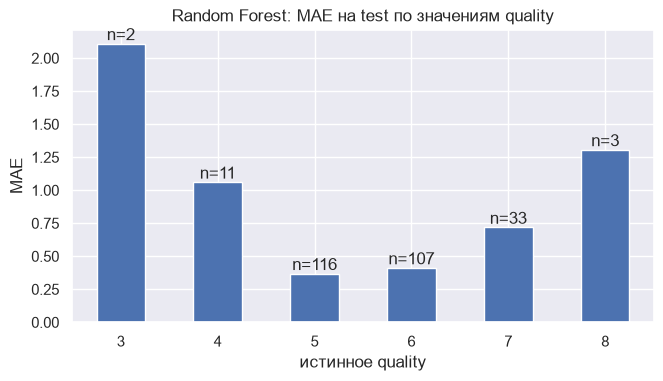

In [37]:
# качество прогноза отдельно для каждого значения quality
by_quality = (
    pd.DataFrame({"quality": y_test, "pred": pred, "err": error})
    .groupby("quality")
    .agg(
        n=("err", "size"),
        средний_прогноз=("pred", "mean"),
        смещение=("err", "mean"),
        MAE=("err", lambda e: e.abs().mean()),
        RMSE=("err", lambda e: np.sqrt((e ** 2).mean())),
    )
)
by_quality["доля в train, %"] = y_train.value_counts(normalize=True).reindex(by_quality.index) * 100
display(by_quality.round(3))

ax = by_quality["MAE"].plot.bar(figsize=(7.5, 3.8), rot=0)
ax.bar_label(ax.containers[0], labels=[f"n={n}" for n in by_quality["n"]])
ax.set_xlabel("истинное quality")
ax.set_ylabel("MAE")
ax.set_title(f"{best_name}: MAE на test по значениям quality")
plt.show()

**Вывод:** модель работает неодинаково:
- на классах 5 и 6 (82% test) MAE ≈ 0.4;
- на классе 7 - 0.72;
- на редких классах ошибка 1-2 балла (класс 4 - 1.06, класс 8 - 1.31, класс 3 - 2.11).

Чем реже класс в train, тем больше ошибка. Редких вин в test мало (16), поэтому общий RMSE выглядит хорошо, хотя на них модель почти не работает.

In [38]:
# 10 вин с самой большой ошибкой и значения ключевых признаков
worst_idx = abs_error.sort_values(ascending=False).index[:10]
worst = pd.DataFrame({
    "quality": y_test[worst_idx],
    "прогноз": pred[worst_idx],
    "ошибка": error[worst_idx],
}).join(X_test.loc[worst_idx, top_features])
worst.round(3)

,quality,прогноз,ошибка,alcohol,sulphates,volatile acidity,total sulfur dioxide
832,3,5.187,2.187,9.9,0.86,0.440,48.0
1374,3,5.033,2.033,9.8,0.51,0.815,29.0
7,7,5.010,-1.990,10.0,0.47,0.650,21.0
703,4,5.810,1.810,9.6,0.70,0.380,84.0
495,8,6.390,-1.610,11.0,0.65,0.350,16.0
1466,7,5.433,-1.567,10.0,0.65,0.480,54.0
645,7,5.513,-1.487,10.1,0.69,0.640,11.0
1233,4,5.447,1.447,9.3,0.49,0.230,36.0
473,5,6.437,1.437,10.6,0.79,0.350,14.0
1147,7,5.637,-1.363,11.8,0.49,0.410,14.0


Почти все крупные ошибки - на винах с нетипичными оценками (3, 4, 7, 8).

In [39]:
# сравниваем 4 самых крупных ошибки с «типичным» вином (медиана train) их истинного класса
# и класса, который ближе всего к прогнозу
profile_rows = []
for idx in worst_idx[:4]:
    true_q = int(y_test[idx])
    pred_q = int(np.clip(round(pred[idx]), y_train.min(), y_train.max()))
    profile_rows.append(X_test.loc[idx, top_features].rename(f"вино {idx}: quality={true_q}, прогноз={pred[idx]:.2f}"))
    profile_rows.append(class_medians.loc[true_q, top_features].rename(f"    медиана train, quality={true_q}"))
    profile_rows.append(class_medians.loc[pred_q, top_features].rename(f"    медиана train, quality={pred_q}"))
pd.DataFrame(profile_rows).round(3)

,alcohol,sulphates,volatile acidity,total sulfur dioxide
"вино 832: quality=3, прогноз=5.19",9.900,0.860,0.440,48.0
"медиана train, quality=3",10.075,0.545,0.928,14.0
"медиана train, quality=5",9.600,0.580,0.590,48.0
"вино 1374: quality=3, прогноз=5.03",9.800,0.510,0.815,29.0
"медиана train, quality=3",10.075,0.545,0.928,14.0
"медиана train, quality=5",9.600,0.580,0.590,48.0
"вино 7: quality=7, прогноз=5.01",10.000,0.470,0.650,21.0
"медиана train, quality=7",11.550,0.740,0.360,26.5
"медиана train, quality=5",9.600,0.580,0.590,48.0
"вино 703: quality=4, прогноз=5.81",9.600,0.700,0.380,84.0


**Разбор:** сравниваем вино с медианой train для его истинного класса и для класса, близкого к прогнозу.
- **Вино 832 (quality 3, прогноз 5.19):** по признакам выглядит как нормальное вино - низкая летучая кислотность (0.44), много сульфатов (0.86). Низкую оценку химия не объясняет: возможно, дефект, который не измерен, или ошибка в оценке.
- **Вино 1374 (quality 3, прогноз 5.03):** высокая летучая кислотность (0.815) - признак плохого вина, и модель снизила прогноз, но не до 3: в train всего 8 таких вин, поэтому рядом с ним в листьях деревьев в основном вина класса 5.
- **Вино 7 (quality 7, прогноз 5.01):** по алкоголю (10%), сульфатам (0.47) и летучей кислотности (0.65) похоже на типичное вино класса 5.
- **Вино 703 (quality 4, прогноз 5.81):** низкая летучая кислотность и много сульфатов - как у вин 6-7.

**Общая причина:** у этих вин признаки типичны для другого класса, поэтому модель ошибается.

### Почему хуже предсказываются редкие значения quality
- **Мало примеров:** в train 8 вин класса 3 и 14 класса 8 - этого недостаточно, чтобы выучить их особенности.
- **Ошибка обучения (MSE) в основном состоит из ошибок на винах 5-6**, поэтому модель подстраивается под них.
- **Усреднение в лесе** стягивает прогноз к центру: чтобы предсказать 3, почти все деревья должны «увидеть» тройку.
- **Шум и неизмеренные факторы:** оценка субъективна, а аромат, сорт винограда и т. п. в данных отсутствуют.

## 14. Модель для скрытого теста
- `predict_quality(data)` принимает таблицу в формате UCI (столбец `quality`, если он есть, игнорируется) и возвращает прогнозы.
- Лучшая модель (Random Forest), обученная на train, сохраняется в `model.joblib` - та самая, метрики которой приведены в разделе 11.

In [40]:
def predict_quality(data, model=None, is_red=None):
    """
    Предсказывает quality для таблицы в формате UCI (столбцы как в winequality-*.csv).
    Столбец quality, если он есть, игнорируется. Для модели, обученной при WINE_TYPE="all",
    в данных нужен столбец is_red - либо его можно передать параметром (1 - красное, 0 - белое).
    """
    if model is None:
        model = joblib.load(MODEL_PATH)
    features = list(model.feature_names_in_)  # признаки в том порядке, в котором училась модель
    data = data.copy()
    if "is_red" in features and "is_red" not in data.columns:
        if is_red is None:
            raise ValueError("Модель обучена на red+white: передайте is_red=1 (красное) или is_red=0 (белое)")
        data["is_red"] = int(is_red)
    missing = [f for f in features if f not in data.columns]
    if missing:
        raise ValueError(f"В данных нет признаков: {missing}")
    return model.predict(data[features])


joblib.dump(best_model, MODEL_PATH)
print(f"Сохранена модель {best_name!r} (обучена на train) -> {MODEL_PATH}")

Сохранена модель 'Random Forest' (обучена на train) -> model.joblib


Для применения достаточно `joblib.load` и `predict_quality` - заново обучать ничего не нужно.

In [41]:
# Демонстрация: загружаем модель из файла и предсказываем для таблицы в формате UCI.
# В роли «новых данных» - строки нашего test, прочитанные заново из исходного CSV (вместе со столбцом quality).
loaded_model = joblib.load(MODEL_PATH)
new_data = load_wine(WINE_TYPE).loc[X_test.index]

new_pred = predict_quality(new_data, model=loaded_model)
display(new_data.head(5).assign(predicted_quality=new_pred[:5].round(2)))

print(f"RMSE на этих строках: {root_mean_squared_error(new_data[TARGET], new_pred):.4f}")
assert np.allclose(new_pred, test_pred[best_name]), "модель из файла должна давать те же прогнозы"
print("Прогнозы модели из файла совпадают с прогнозами в разделе 11.")

# Для скрытого теста в виде CSV:
# hidden = pd.read_csv("hidden_test.csv", sep=";")
# hidden_pred = predict_quality(hidden)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,predicted_quality
1152,8.3,0.600,0.25,2.2,0.118,9.0,38.0,0.9962,3.15,0.53,9.8,5,5.14
1495,7.0,0.430,0.02,1.9,0.080,15.0,28.0,0.9949,3.35,0.81,10.6,6,5.81
68,9.3,0.320,0.57,2.0,0.074,27.0,65.0,0.9969,3.28,0.79,10.7,5,6.17
1202,8.6,0.420,0.39,1.8,0.068,6.0,12.0,0.9952,3.35,0.69,11.7,8,6.72
1034,8.9,0.745,0.18,2.5,0.077,15.0,48.0,0.9974,3.20,0.47,9.7,6,5.09


RMSE на этих строках: 0.6264
Прогнозы модели из файла совпадают с прогнозами в разделе 11.


**Проверка:** модель из файла даёт те же прогнозы и тот же RMSE (0.6264), что и в итоговой таблице.

## 15. Итоги
- **Данные:** удалено 240 дубликатов (15%), осталось 1359 вин; разбиение 80/20 со стратификацией по `quality`.
- **Результаты на test:**

| Модель | RMSE | MAE |
|---|---|---|
| Random Forest | 0.626 | 0.480 |
| Gradient Boosting | 0.634 | 0.496 |
| Linear Regression (Ridge) | 0.655 | 0.511 |
| Baseline (mean) | 0.819 | 0.692 |

- Все модели лучше baseline и проходят порог 0.70. **Лучшая - Random Forest**: выбрана по CV (0.644), на test RMSE = 0.626.
- **Главные признаки** во всех моделях и в EDA: `alcohol`, `sulphates`, `volatile acidity`.
- **Ошибки:** на винах 5-6 модель точна (MAE ≈ 0.4), на редких оценках 3, 4, 8 ошибается на 1-2 балла и тянет прогноз к среднему.
- **Ограничения:** оценка субъективна, химических признаков недостаточно; на отдельных выборках RMSE может быть выше (на одном из фолдов CV - 0.708). Улучшить модель можно подбором гиперпараметров (лабораторная №3).

## 16. Ответы на вопросы из ТЗ

**1. Какой размер обучающей и тестовой выборки?** 80/20: 1087 и 272 вина - достаточно данных для обучения и достаточно объектов для устойчивой оценки.

**2. Почему такой способ разбиения?** Стратификация по `quality` сохраняет доли редких классов в обеих выборках; `random_state=42` делает разбиение воспроизводимым.

**3. Чем плохо многократно оценивать модели на одной тестовой выборке?** Решение подстраивается под этот test, и оценка становится завышенной. Поэтому все решения принимались по кросс-валидации на train.

**4. Какую константу использовать для baseline?** Среднее `quality` на train (5.626) - оно минимизирует RMSE. Для MAE оптимальна медиана.

**5. Что показывает MAE?** Среднюю ошибку в баллах; у лучшей модели - 0.48.

**6. Что показывает RMSE?** Типичную ошибку с повышенным весом крупных промахов; у лучшей модели - 0.626.

**7. Почему RMSE сильнее реагирует на большие ошибки?** Из-за возведения в квадрат: ошибка 2 даёт вклад 4, а ошибка 0.5 - только 0.25.

**8. Почему MAE и RMSE могут заметно различаться?** RMSE ≥ MAE, и разница растёт, когда есть крупные ошибки. У леса RMSE/MAE ≈ 1.31 из-за промахов на редких винах.

**9. Нужно ли масштабирование для линейной регрессии?** Да: без него коэффициенты зависят от единиц измерения и их нельзя сравнивать, а штраф Ridge действует на признаки неравномерно.

**10. Какие признаки сильнее всего влияют на прогноз линейной модели?** `alcohol` (+0.28), `volatile acidity` (-0.18), `sulphates` (+0.14).

**11. Какие модели превзошли baseline и почему они различаются?** Все три. Деревья учитывают нелинейные зависимости и поэтому лучше Ridge; лес немного лучше бустинга (на 4 из 5 фолдов).

**12. Какие признаки важны для RF и GB и совпадает ли это с EDA?** У обеих моделей - `alcohol`, `sulphates`, `volatile acidity`, затем `total sulfur dioxide`. Первые три совпадают с EDA.

**13. Можно ли по feature importance утверждать, что признак - причина изменения качества?** Нет: это статистическая связь в данных, возможны скрытые общие причины, а важность зависит от модели.

**14. Почему модель хуже предсказывает редкие значения quality?** Мало примеров, ошибка обучения определяется массовыми классами 5-6, а усреднение в лесе тянет прогноз к центру.

**15. Почему дубликаты удалены до разбиения?** Чтобы одно вино не попало одновременно в train и test. Это не утечка: статистики не вычисляются, удаляются только одинаковые строки.